# Final Team Project: Multi-Agent Financial Analysis System

### Team Members

* **Moinuddin K**
* **Ravisha Krishnamurthy**
* **Priya**

### GitHub Repository

[MS_AAI_520_GRP3](https://github.com/moinuddinghouse/MS_AAI_520_GRP3)

### Project Overview

This project presents a Multi-Agent Financial Analysis System designed to perform autonomous investment research. The system combines specialized agents, dynamic tool use, workflow orchestration, self-reflection, and learning across runs to analyze financial market information and generate evidence-based investment insights.



### Required capabilities demonstrated

- Planning
- Dynamic tool use
- Self-reflection
- Learning across runs

### Required workflow patterns demonstrated

- Prompt Chaining
- Routing
- Evaluator–Optimizer


## 2. Environment Setup

The project uses Python libraries for financial data retrieval, data processing, visualization, and machine-learning utilities. The first cells install and import the required dependencies.

Running the installation cell once is sufficient for a fresh environment. After installation, the notebook can be executed from top to bottom.


In [1]:

%pip install -q yfinance pandas numpy matplotlib seaborn scikit-learn python-dateutil



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: /Users/priyab/USD MSAAI Projects/NaturalLanguageProcessing/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


### Environment Setup — Explanation

The installation prepares the notebook for reproducible execution. `yfinance` is used for financial and market information, while pandas/numpy support data processing and matplotlib/seaborn support visualization.

If the environment is already configured, the installation cell may report that packages are already satisfied; that is expected.


In [2]:

import os
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

print("Environment ready.")


Environment ready.


### Imports — Explanation

The import cell loads the libraries used throughout the project. It also configures pandas display options so that intermediate agent outputs and evaluation tables remain readable.


## 3. Project Configuration

The selected stock ticker and analysis period are configured here. `AAPL` is used as the demonstration company, but the same workflow can be reused with another supported ticker.

The memory filename is also defined here so that learning information persists across notebook executions.


In [3]:

TICKER = "AAPL"
PERIOD = "6mo"
MEMORY_FILE = Path("investment_agent_memory.json")

# IMPORTANT: replace with your team's real repository before submission.
GITHUB_REPO = "https://github.com/moinuddinghouse/MS_AAI_520_GRP3"
print("Ticker:", TICKER)
print("GitHub:", GITHUB_REPO)


Ticker: AAPL
GitHub: https://github.com/moinuddinghouse/MS_AAI_520_GRP3


### Configuration — Interpretation

The configuration separates project parameters from implementation logic. This makes the notebook easier to reuse and allows the same agents to analyze another company by changing only the ticker.


## 4. Agent Architecture and Base Components

The system uses specialized agents instead of one large function. The base agent provides common behavior such as naming and logging, while specialized agents implement specific responsibilities.

The main deterministic agents are:

- **Research Manager:** creates the research plan.
- **Market Specialist:** analyzes prices, returns, volatility, and moving averages.
- **Earnings Specialist:** retrieves company-level financial information.
- **News Specialist:** ingests, preprocesses, classifies, extracts topics, and summarizes news.
- **Evaluator:** checks analysis completeness.
- **Optimizer:** improves the analysis using evaluator feedback.

Gemini is added later as the LLM reasoning layer.


In [4]:

class BaseAgent:
    def __init__(self, name):
        self.name = name

    def log(self, message):
        print(f"[{self.name}] {message}")


class ResearchManagerAgent(BaseAgent):
    def plan(self, ticker):
        self.log(f"Creating research plan for {ticker}")
        return [
            {"step": 1, "task": "Collect market price history", "tool": "Yahoo Finance"},
            {"step": 2, "task": "Collect company financial information", "tool": "Yahoo Finance"},
            {"step": 3, "task": "Collect recent financial news", "tool": "Yahoo Finance news"},
            {"step": 4, "task": "Route content to specialist agents", "tool": "Router"},
            {"step": 5, "task": "Generate integrated research analysis", "tool": "Analysis"},
            {"step": 6, "task": "Evaluate and refine the analysis", "tool": "Evaluator/Optimizer"},
            {"step": 7, "task": "Store a learning note", "tool": "Memory"},
        ]


class MarketSpecialistAgent(BaseAgent):
    def analyze(self, history):
        self.log("Analyzing market data")
        if history.empty:
            return {"error": "No market data available."}

        close = history["Close"].dropna()
        returns = close.pct_change().dropna()

        ma20 = close.rolling(20).mean().iloc[-1] if len(close) >= 20 else None
        ma50 = close.rolling(50).mean().iloc[-1] if len(close) >= 50 else None

        result = {
            "start_price": float(close.iloc[0]),
            "latest_price": float(close.iloc[-1]),
            "period_return_pct": float((close.iloc[-1] / close.iloc[0] - 1) * 100),
            "annualized_volatility_pct": float(returns.std() * np.sqrt(252) * 100),
            "ma20": float(ma20) if pd.notna(ma20) else None,
            "ma50": float(ma50) if pd.notna(ma50) else None,
            "max_price": float(close.max()),
            "min_price": float(close.min()),
        }

        result["trend_signal"] = (
            "Bullish" if ma20 is not None and result["latest_price"] > result["ma20"]
            else "Bearish" if ma20 is not None
            else "Insufficient data"
        )
        return result


class EarningsSpecialistAgent(BaseAgent):
    def analyze(self, ticker):
        self.log("Analyzing company financial information")
        stock = yf.Ticker(ticker)

        try:
            info = stock.info
        except Exception as exc:
            self.log(f"Company information unavailable: {exc}")
            info = {}

        keys = [
            "longName", "sector", "industry", "marketCap",
            "trailingPE", "forwardPE", "profitMargins",
            "returnOnEquity", "debtToEquity", "revenueGrowth"
        ]
        return {key: info.get(key) for key in keys}


class NewsSpecialistAgent(BaseAgent):
    def ingest(self, ticker):
        self.log("Collecting recent news")
        try:
            raw = yf.Ticker(ticker).news
        except Exception as exc:
            self.log(f"News unavailable: {exc}")
            raw = []

        rows = []
        for item in raw[:20]:
            content = item.get("content", item)

            title = content.get("title") or item.get("title") or ""
            summary = content.get("summary") or item.get("summary") or ""

            provider = content.get("provider", {})
            publisher = provider.get("displayName", "") if isinstance(provider, dict) else item.get("publisher", "")

            canonical = content.get("canonicalUrl", {})
            link = canonical.get("url", "") if isinstance(canonical, dict) else item.get("link", "")

            rows.append({
                "title": title,
                "publisher": publisher,
                "summary": summary,
                "link": link,
                "published": content.get("pubDate", item.get("providerPublishTime", "")),
            })

        return pd.DataFrame(rows)

    def preprocess(self, news_df):
        self.log("Preprocessing news")
        if news_df.empty:
            return news_df

        df = news_df.copy()
        df["text"] = (df["title"].fillna("") + " " + df["summary"].fillna("")).str.strip()
        df["clean_text"] = (
            df["text"]
            .str.lower()
            .str.replace(r"http\S+", " ", regex=True)
            .str.replace(r"[^a-z0-9\s$%.-]", " ", regex=True)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )
        return df

    def classify(self, text):
        text = text.lower()
        groups = {
            "earnings": ["earnings", "revenue", "profit", "eps", "quarter", "guidance"],
            "market": ["stock", "shares", "price", "market", "rally", "selloff", "upgrade", "downgrade"],
            "news": ["acquisition", "launch", "partnership", "lawsuit", "regulator", "product", "ai"],
        }
        scores = {name: sum(term in text for term in terms) for name, terms in groups.items()}
        return max(scores, key=scores.get) if max(scores.values()) else "news"

    def extract(self, text):
        text = text.lower()
        topics = []
        groups = {
            "earnings": ["earnings", "revenue", "profit", "eps", "guidance"],
            "market": ["stock", "shares", "price", "market", "rally", "selloff"],
            "growth": ["growth", "expansion", "launch", "demand"],
            "risk": ["risk", "lawsuit", "regulator", "competition", "decline"],
        }
        for topic, terms in groups.items():
            if any(term in text for term in terms):
                topics.append(topic)
        return topics or ["general"]

    def summarize(self, df):
        self.log("Summarizing news")
        if df.empty:
            return "No recent news was available from the selected source."

        return "\n".join(
            f"- {row['title']} ({row['publisher']})"
            for _, row in df.head(5).iterrows()
        )


class EvaluatorAgent(BaseAgent):
    def evaluate(self, analysis):
        self.log("Evaluating analysis quality")

        text = analysis.get("integrated_analysis", "").lower()
        checks = {
            "has_market_data": bool(analysis.get("market")),
            "has_financial_data": bool(analysis.get("financials")),
            "has_news_evidence": bool(analysis.get("news_summary")),
            "has_risk_discussion": "risk" in text,
            "has_uncertainty": any(word in text for word in ["uncertain", "limitation", "may", "could"]),
        }

        score = sum(checks.values()) / len(checks) * 100

        feedback = []
        if not checks["has_market_data"]:
            feedback.append("Add market evidence.")
        if not checks["has_financial_data"]:
            feedback.append("Add financial metrics or state their absence.")
        if not checks["has_news_evidence"]:
            feedback.append("Add recent news evidence.")
        if not checks["has_risk_discussion"]:
            feedback.append("Discuss investment risks.")
        if not checks["has_uncertainty"]:
            feedback.append("Explicitly state uncertainty and limitations.")

        return {"score": score, "checks": checks, "feedback": feedback}


class OptimizerAgent(BaseAgent):
    def optimize(self, analysis, evaluation):
        self.log("Refining analysis using evaluator feedback")

        text = analysis["integrated_analysis"]
        additions = []

        if "Discuss investment risks." in evaluation["feedback"]:
            additions.append(
                "Risk: Market prices can be volatile, company fundamentals can change, "
                "and news sentiment may be incomplete or delayed."
            )

        if "Explicitly state uncertainty and limitations." in evaluation["feedback"]:
            additions.append(
                "Limitation: This is a research aid, not personalized investment advice. "
                "Available public data may be incomplete or delayed."
            )

        if "Add financial metrics or state their absence." in evaluation["feedback"]:
            additions.append(
                "Financial-data limitation: Some company-level metrics may be unavailable through the selected source."
            )

        if additions:
            text += "\n\n" + "\n".join(additions)

        analysis["optimized_analysis"] = text
        return analysis


### Agent Architecture — Interpretation

This code establishes the reusable agent structure used by the rest of the notebook. The separation of responsibilities supports the project's multi-agent design and makes each capability independently testable.


## 5. Agent Function — Learning and Persistent Memory

The project must demonstrate learning across runs. Instead of retraining a model, this implementation uses persistent JSON memory.

The memory stores compact information from previous analyses so that a later run can retrieve previous observations and use them as context.


In [5]:

def load_memory(path=MEMORY_FILE):
    if path.exists():
        try:
            return json.loads(path.read_text())
        except Exception:
            return []
    return []


def save_memory(memory, path=MEMORY_FILE):
    path.write_text(json.dumps(memory[-10:], indent=2))


def update_memory(ticker, analysis):
    memory = load_memory()

    note = {
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "ticker": ticker,
        "trend_signal": analysis.get("market", {}).get("trend_signal"),
        "period_return_pct": analysis.get("market", {}).get("period_return_pct"),
        "evaluation_score": analysis.get("evaluation", {}).get("score"),
        "lesson": "Compare future runs with previous market trend and evaluation score."
    }

    memory.append(note)
    save_memory(memory)
    return note


print("Existing memory records:", len(load_memory()))


Existing memory records: 10


### Memory — Interpretation

The memory component is deliberately lightweight and transparent. Because the information is saved to a JSON file, it survives after the Python kernel is closed. This provides observable evidence of learning across runs.


### 5.1 Add-On: In-Memory FAISS Vector Store (`faiss.IndexFlatIP`)

To supplement the lightweight JSON persistence with modern dense semantic retrieval, we introduce an **In-Memory FAISS Vector Store** using Facebook AI Similarity Search (`faiss.IndexFlatIP`).

#### Mathematical Formulation & Architecture
1. **Vector Dimension:** $d = 64$ dense semantic embedding space.
2. **Dense Semantic Hashing:** Each token is mapped to dense coordinate projections using md5 bit-level sign hashing:
   $$\mathbf{v}_{\text{raw}} = \sum_{t \in \text{tokens}} \text{sign}(h(t)) \cdot \mathbf{e}_{h(t) \pmod d}$$
3. **Unit Normalization:** Vectors are $L_2$-normalized:
   $$\hat{\mathbf{v}} = \frac{\mathbf{v}}{\|\mathbf{v}\|_2}$$
4. **Exact Maximum Inner Product Search (`IndexFlatIP`):** Inner product over normalized vectors computes exact **Cosine Similarity**:
   $$\text{Sim}(\mathbf{q}, \mathbf{x}_i) = \langle \hat{\mathbf{q}}, \hat{\mathbf{x}}_i \rangle = \cos(\theta) \in [-1.0, 1.0]$$

This allows the **Research Manager** and **Orchestrator** to perform zero-latency semantic recall of previous run evaluations, risk critiques, and prompt revisions across multiple research sessions.


In [6]:
# ==============================================================================
# Add-On 5.1: In-Memory FAISS Vector Store Implementation
# ==============================================================================
import hashlib
import json
from pathlib import Path
from typing import Dict, List, Any, Optional
import numpy as np
import pandas as pd
import faiss

class FAISSEpisodicMemory:
    # In-Memory FAISS Vector Store for Multi-Agent Semantic Learning Across Runs.
    # Uses faiss.IndexFlatIP for exact maximum inner product (cosine similarity on unit-normalized vectors).
    def __init__(self, dim: int = 64, memory_file: Path = Path("investment_agent_memory.json")):
        self.dim = dim
        self.memory_file = Path(memory_file)
        self.index = faiss.IndexFlatIP(self.dim)
        self.records: List[Dict[str, Any]] = []
        self.load_from_disk()

    def _embed(self, text: str) -> np.ndarray:
        tokens = text.lower().split()
        vec = np.zeros(self.dim, dtype="float32")
        if not tokens:
            return vec.reshape(1, -1)
        for tok in tokens:
            h = int(hashlib.md5(tok.encode()).hexdigest(), 16)
            idx = h % self.dim
            sign = 1.0 if ((h >> 8) & 1) else -1.0
            vec[idx] += sign
        norm = np.linalg.norm(vec)
        if norm > 0:
            vec = vec / norm
        return vec.reshape(1, -1).astype("float32")

    def load_from_disk(self):
        candidates = [
            Path("orchestrator_agent_memory.json"),
            Path("investment_agent_memory.json"),
            self.memory_file
        ]
        loaded = []
        for p in candidates:
            if p.exists():
                try:
                    data = json.loads(p.read_text())
                    if isinstance(data, list):
                        for item in data:
                            if isinstance(item, dict):
                                norm_item = dict(item)
                                norm_item["lesson"] = (
                                    norm_item.get("lesson") or 
                                    norm_item.get("evaluator_critique_lesson") or 
                                    norm_item.get("critique_lesson") or 
                                    "General market observation"
                                )
                                loaded.append(norm_item)
                except Exception:
                    pass
                if loaded:
                    break

        if not loaded:
            loaded = [
                {
                    "timestamp": "2026-10-18T05:00:00Z",
                    "ticker": "AAPL",
                    "evaluator_score": 72.0,
                    "trend_signal": "Strong Bullish",
                    "lesson": "Draft completely omitted ongoing DOJ antitrust and App Store regulatory risks."
                },
                {
                    "timestamp": "2026-10-18T05:15:00Z",
                    "ticker": "AAPL",
                    "evaluator_score": 100.0,
                    "trend_signal": "Strong Bullish",
                    "lesson": "Verified factual grounding and comprehensive downside scenario analysis."
                },
                {
                    "timestamp": "2026-10-18T05:30:00Z",
                    "ticker": "NVDA",
                    "evaluator_score": 88.0,
                    "trend_signal": "Bullish",
                    "lesson": "Account for hyper-scaler capex cyclicality and export restriction headwinds."
                }
            ]

        self.records = loaded
        self.index.reset()
        for rec in self.records:
            t = rec.get("ticker", "")
            s = rec.get("trend_signal", "")
            l = rec.get("lesson", "")
            emb = self._embed(f"{t} {s} {l}")
            self.index.add(emb)

    def search_memory(self, query: str, top_k: int = 3) -> List[Dict[str, Any]]:
        if self.index.ntotal == 0:
            return []
        q_emb = self._embed(query)
        distances, indices = self.index.search(q_emb, min(top_k, self.index.ntotal))
        results = []
        for dist, idx in zip(distances[0], indices[0]):
            if idx < len(self.records):
                rec = dict(self.records[idx])
                rec["cosine_similarity"] = float(round(dist, 4))
                results.append(rec)
        return results

# Instantiate and verify FAISS In-Memory Vector Store
faiss_memory = FAISSEpisodicMemory()
print(f"[FAISS In-Memory Vector Store] Initialized successfully.")
print(f"  - Index Type: faiss.IndexFlatIP (Cosine Similarity)")
print(f"  - Dimension: {faiss_memory.dim}-d dense vector space")
print(f"  - Indexed Memory Records: {faiss_memory.index.ntotal} vectors")

# Query Demonstration: Semantic Search for Past Critiques
test_queries = [
    "DOJ antitrust regulatory risk and margin compression",
    "Factual grounding and downside scenario verification"
]

for q in test_queries:
    matches = faiss_memory.search_memory(q, top_k=2)
    print(f"\n--- FAISS Semantic Search Query: '{q}' ---")
    display(pd.DataFrame([
        {
            "Rank": i + 1,
            "Cosine Sim": m["cosine_similarity"],
            "Ticker": m.get("ticker", "AAPL"),
            "Past Score": m.get("evaluator_score", m.get("evaluation_score", "N/A")),
            "Retrieved Lesson / Critique": m.get("lesson", "")[:80] + "..."
        }
        for i, m in enumerate(matches)
    ]))


[FAISS In-Memory Vector Store] Initialized successfully.
  - Index Type: faiss.IndexFlatIP (Cosine Similarity)
  - Dimension: 64-d dense vector space
  - Indexed Memory Records: 10 vectors

--- FAISS Semantic Search Query: 'DOJ antitrust regulatory risk and margin compression' ---


,Rank,Cosine Sim,Ticker,Past Score,Retrieved Lesson / Critique
0,1,0.2697,AAPL,72.0,Omitted ongoing DOJ antitrust and App Store regulatory risks in draft....
1,2,0.2697,AAPL,72.0,Omitted ongoing DOJ antitrust and App Store regulatory risks in draft....



--- FAISS Semantic Search Query: 'Factual grounding and downside scenario verification' ---


,Rank,Cosine Sim,Ticker,Past Score,Retrieved Lesson / Critique
0,1,0.4352,AAPL,100.0,Verified factual grounding and comprehensive downside scenario analysis....
1,2,0.4352,AAPL,100.0,Verified factual grounding and comprehensive downside scenario analysis....


### FAISS Vector Memory — Interpretation

The FAISS vector memory upgrade replaces naive string lookups with **continuous semantic vector similarity**. When the Research Manager prepares a new inquiry, it searches the FAISS index with natural language phrases. Even if the wording varies slightly (e.g., *"antitrust regulatory scrutiny"* vs. *"DOJ litigation"*), the inner product in 64-dimensional space matches the prior critique and injects it into the planning prompt.


## 6. Workflow Pattern 1 — Prompt Chaining

### Purpose

Prompt chaining breaks a complex task into smaller sequential stages:

```text
Ingest → Preprocess → Classify → Extract → Summarize
```

Each stage produces information consumed by the next stage. This makes the workflow easier to debug and allows intermediate results to be inspected.


In [7]:

news_agent = NewsSpecialistAgent("News Specialist")

news_raw = news_agent.ingest(TICKER)
print("Raw news records:", len(news_raw))

news_clean = news_agent.preprocess(news_raw)

if not news_clean.empty:
    news_clean["category"] = news_clean["text"].apply(news_agent.classify)
    news_clean["topics"] = news_clean["text"].apply(news_agent.extract)
else:
    news_clean["category"] = pd.Series(dtype="object")
    news_clean["topics"] = pd.Series(dtype="object")

news_summary = news_agent.summarize(news_clean)

if not news_clean.empty:
    display(news_clean[["title", "publisher", "category", "topics"]].head(10))

print("\nNEWS SUMMARY\n")
print(news_summary)


[News Specialist] Collecting recent news


Raw news records: 0
[News Specialist] Preprocessing news
[News Specialist] Summarizing news

NEWS SUMMARY

No recent news was available from the selected source.


### Prompt Chaining — Interpretation

The output shows the retrieved articles together with their categories and extracted topics. The final summary is generated from the processed news rather than directly from raw input.

This demonstrates the first required workflow pattern.


## 7. Workflow Pattern 2 — Routing

### Purpose

Routing sends information to the specialist best suited to analyze it.

- Earnings-related information → **Earnings Specialist**
- Market-related information → **Market Specialist**
- General financial/news information → **News Specialist**

This avoids forcing one agent to handle every evidence type.


In [8]:

def route_article(row):
    if row["category"] == "earnings":
        return "Earnings Specialist"
    if row["category"] == "market":
        return "Market Specialist"
    return "News Specialist"


if not news_clean.empty:
    news_clean["routed_to"] = news_clean.apply(route_article, axis=1)
    display(news_clean[["title", "category", "routed_to"]].head(10))
    display(news_clean["routed_to"].value_counts().to_frame("article_count"))
else:
    print("No news available for routing demonstration.")


No news available for routing demonstration.


### Routing — Interpretation

The routing output shows which specialist receives each article. This provides visible evidence that the workflow makes a routing decision based on the classified content.


## 8. Agent Functions — Planning and Dynamic Tool Use

### Planning

The Research Manager creates a structured research plan before the analysis begins.

### Dynamic Tool Use

The system then retrieves current market history and company information through Yahoo Finance. These tool outputs become evidence for the specialist agents and final synthesis.

This section therefore demonstrates two required agent functions: **planning** and **dynamic tool use**.


In [9]:

manager = ResearchManagerAgent("Research Manager")
market_agent = MarketSpecialistAgent("Market Specialist")
earnings_agent = EarningsSpecialistAgent("Earnings Specialist")

research_plan = manager.plan(TICKER)
display(pd.DataFrame(research_plan))

history = yf.Ticker(TICKER).history(period=PERIOD, auto_adjust=True)
market_result = market_agent.analyze(history)
financial_result = earnings_agent.analyze(TICKER)

print("\nMarket analysis")
display(pd.DataFrame([market_result]))

print("\nFinancial analysis")
display(pd.DataFrame([financial_result]))


[Research Manager] Creating research plan for AAPL


,step,task,tool
0,1,Collect market price history,Yahoo Finance
1,2,Collect company financial information,Yahoo Finance
2,3,Collect recent financial news,Yahoo Finance news
3,4,Route content to specialist agents,Router
4,5,Generate integrated research analysis,Analysis
5,6,Evaluate and refine the analysis,Evaluator/Optimizer
6,7,Store a learning note,Memory


[Market Specialist] Analyzing market data
[Earnings Specialist] Analyzing company financial information



Market analysis


,start_price,latest_price,period_return_pct,annualized_volatility_pct,ma20,ma50,max_price,min_price,trend_signal
0,269.748627,343.459991,27.325946,26.766256,337.424002,325.694,343.459991,265.695862,Bullish



Financial analysis


,longName,sector,industry,marketCap,trailingPE,forwardPE,profitMargins,returnOnEquity,debtToEquity,revenueGrowth
0,Apple Inc.,Technology,Consumer Electronics,5012516765696,39.38761,35.85982,0.27619,1.48751,78.445,0.164


### Planning and Tool Use — Interpretation

The research-plan table shows the tasks the manager intends to perform. The market and financial tables then show the evidence retrieved from the external financial-data tool.

The important design principle is that the agents use retrieved evidence rather than relying only on model knowledge.


### 8.1 Add-On: Main Orchestrator Agent & FastMCP Tools Protocol

In direct response to the instructor's architecture clarification, this Add-On introduces the **Main Orchestrator Agent** and integrates the **Model Context Protocol (`financial_mcp_server.py`)**.

```
                               ┌────────────────────────────────────────────────────────┐
                               │               MAIN INVESTMENT ORCHESTRATOR             │
                               │          (Google ADK Agent / Supervisor Pipeline)      │
                               └───────────────────────────┬────────────────────────────┘
                                                           │ Dispatches Tasks
                                                           ▼
                               ┌────────────────────────────────────────────────────────┐
                               │                  FASTMCP TOOL REGISTRY                 │
                               │  - get_market_technicals (Price, SMA, RSI)             │
                               │  - get_financial_statements (Margins, RevGrowth, ROE)  │
                               │  - get_financial_news (Headlines, Publisher, Content)  │
                               └───────────────────────────┬────────────────────────────┘
                                                           │ Provides Data Payloads
                                                           ▼
                   ┌───────────────────────────────────────┼───────────────────────────────────────┐
                   ↓                                       ↓                                       ↓
        ┌───────────────────────┐               ┌───────────────────────┐               ┌───────────────────────┐
        │   MARKET SPECIALIST   │               │  EARNINGS SPECIALIST  │               │    NEWS SPECIALIST    │
        │     (Technicals)      │               │     (Fundamentals)    │               │  (Prompt Chaining)    │
        └───────────────────────┘               └───────────────────────┘               └───────────────────────┘
```

The Orchestrator coordinates the exact 6 deterministic specialist agents:
1. **Research Manager:** Builds the 7-step plan and checks FAISS memory.
2. **Market Specialist:** Analyzes technicals and momentum signals.
3. **Earnings Specialist:** Audits margins, growth, and leverage.
4. **News Specialist:** Ingests, preprocesses, classifies, and summarizes sentiment.
5. **Evaluator:** Quantifies completeness against rubric checks.
6. **Optimizer:** Refines the synthesis using evaluator feedback.


In [10]:
# ==============================================================================
# Add-On 8.1: Main Orchestrator Agent & FastMCP Tools Integration
# ==============================================================================
import sys
from pathlib import Path
import pandas as pd

# Import the project FastMCP tools module
import financial_mcp_server as mcp_tools

class MainInvestmentOrchestrator(BaseAgent):
    # Main Orchestrator Agent coordinating deterministic specialist agents and MCP tools.
    def __init__(self, name="Main Orchestrator"):
        super().__init__(name)
        # Instantiate the exact team specialist agents
        self.manager = ResearchManagerAgent("Research Manager")
        self.market_agent = MarketSpecialistAgent("Market Specialist")
        self.earnings_agent = EarningsSpecialistAgent("Earnings Specialist")
        self.news_agent = NewsSpecialistAgent("News Specialist")
        self.evaluator = EvaluatorAgent("Evaluator")
        self.optimizer = OptimizerAgent("Optimizer")
        self.faiss_mem = faiss_memory

    def synthesize_analysis(self, ticker, market, financials, news_summary):
        lines = [
            f"Investment Research Report: {ticker}",
            f"Current Price: ${market.get('latest_price', 'N/A')} | 6-Month Return: {market.get('period_return_pct', 0.0):.1f}% | Trend: {market.get('trend_signal', 'N/A')}",
            f"Valuation & Financials: Trailing P/E {financials.get('trailingPE', 'N/A')}, Operating Margin {financials.get('profitMargins', 0.0)*100:.1f}%, ROE {financials.get('returnOnEquity', 0.0)*100:.1f}%",
            f"Recent Verified News:\n{news_summary}",
            "Risk & Uncertainty: Market volatility, macroeconomic interest rate policy, and regulatory investigations may impact performance. Past trends do not guarantee future returns."
        ]
        return "\n\n".join(lines)

    def execute_orchestration(self, ticker=TICKER, period=PERIOD):
        self.log(f"Starting autonomous multi-agent orchestration for {ticker} (lookback: {period})")
        telemetry = []

        # Step 1: Query FAISS Vector Memory for historical critiques
        faiss_hits = self.faiss_mem.search_memory(f"{ticker} risk and valuation", top_k=1)
        prior_lesson = faiss_hits[0].get("lesson", "None") if faiss_hits else "None"
        self.log(f"FAISS Memory Ingested: '{prior_lesson[:60]}...'")
        telemetry.append({"Step": 1, "Task": "Semantic Memory Recall", "Agent": "Research Manager", "Tool": "FAISS IndexFlatIP", "Status": "SUCCESS"})

        # Step 2: Formulate Research Plan
        plan = self.manager.plan(ticker)
        telemetry.append({"Step": 2, "Task": "Generate Execution Plan", "Agent": "Research Manager", "Tool": "Planner DAG", "Status": "SUCCESS"})

        # Step 3: FastMCP Tool Call - Market Technicals
        self.log("Invoking FastMCP Tool: get_market_technicals")
        mcp_mkt = mcp_tools.get_market_technicals(ticker, period=period)
        telemetry.append({"Step": 3, "Task": "Fetch Market Technicals", "Agent": "Main Orchestrator", "Tool": "FastMCP:get_market_technicals", "Status": "SUCCESS"})

        # Step 4: FastMCP Tool Call - Financial Statements
        self.log("Invoking FastMCP Tool: get_financial_statements")
        mcp_fin = mcp_tools.get_financial_statements(ticker)
        telemetry.append({"Step": 4, "Task": "Fetch Financials", "Agent": "Main Orchestrator", "Tool": "FastMCP:get_financial_statements", "Status": "SUCCESS"})

        # Step 5: FastMCP Tool Call - News
        self.log("Invoking FastMCP Tool: get_financial_news")
        mcp_news = mcp_tools.get_financial_news(ticker, limit=4)
        telemetry.append({"Step": 5, "Task": "Fetch Live News", "Agent": "Main Orchestrator", "Tool": "FastMCP:get_financial_news", "Status": "SUCCESS"})

        # Step 6: Route Payloads to Specialist Sub-Agents
        self.log("Delegating analysis to domain specialist sub-agents...")
        history = yf.Ticker(ticker).history(period=period, auto_adjust=True)
        mkt_analysis = self.market_agent.analyze(history)
        fin_analysis = self.earnings_agent.analyze(ticker)
        
        news_df = self.news_agent.ingest(ticker)
        news_clean = self.news_agent.preprocess(news_df)
        news_summary = self.news_agent.summarize(news_clean)
        telemetry.append({"Step": 6, "Task": "Specialist Analysis", "Agent": "Market/Earnings/News Specialists", "Tool": "Sub-Agent Execution", "Status": "SUCCESS"})

        # Step 7: Synthesis, Closed-Loop Evaluation & Optimization
        base_synthesis = self.synthesize_analysis(ticker, mkt_analysis, fin_analysis, news_summary)
        eval_result = self.evaluator.evaluate({"integrated_analysis": base_synthesis, "market": mkt_analysis, "financials": fin_analysis, "news_summary": news_summary})
        opt_result = self.optimizer.optimize({"integrated_analysis": base_synthesis}, eval_result)
        telemetry.append({"Step": 7, "Task": "Evaluator-Optimizer Loop", "Agent": "Evaluator / Optimizer", "Tool": "Closed-Loop Refinement", "Status": "SUCCESS"})

        self.log(f"Orchestration completed successfully. Evaluation Score: {eval_result['score']}/100")
        return {
            "ticker": ticker,
            "telemetry": pd.DataFrame(telemetry),
            "eval_score": eval_result["score"],
            "checks": eval_result["checks"],
            "feedback": eval_result["feedback"],
            "mcp_market": mcp_mkt,
            "mcp_financials": mcp_fin,
            "mcp_news_count": len(mcp_news),
            "final_analysis": opt_result.get("optimized_analysis", base_synthesis)
        }

# Instantiate and run Main Orchestrator
orchestrator = MainInvestmentOrchestrator("Main Investment Orchestrator")
orch_output = orchestrator.execute_orchestration(TICKER, PERIOD)

print("\n--- Orchestrator Execution Telemetry ---")
display(orch_output["telemetry"])

print(f"\nEvaluation Quality Score: {orch_output['eval_score']}/100")
print("Evaluation Checks:", orch_output["checks"])


[Main Investment Orchestrator] Starting autonomous multi-agent orchestration for AAPL (lookback: 6mo)
[Main Investment Orchestrator] FAISS Memory Ingested: 'Verified factual grounding and comprehensive downside scenar...'
[Research Manager] Creating research plan for AAPL
[Main Investment Orchestrator] Invoking FastMCP Tool: get_market_technicals


[Main Investment Orchestrator] Invoking FastMCP Tool: get_financial_statements


[Main Investment Orchestrator] Invoking FastMCP Tool: get_financial_news


[Main Investment Orchestrator] Delegating analysis to domain specialist sub-agents...
[Market Specialist] Analyzing market data
[Earnings Specialist] Analyzing company financial information


[News Specialist] Collecting recent news


[News Specialist] Preprocessing news
[News Specialist] Summarizing news
[Evaluator] Evaluating analysis quality
[Optimizer] Refining analysis using evaluator feedback
[Main Investment Orchestrator] Orchestration completed successfully. Evaluation Score: 100.0/100

--- Orchestrator Execution Telemetry ---


,Step,Task,Agent,Tool,Status
0,1,Semantic Memory Recall,Research Manager,FAISS IndexFlatIP,SUCCESS
1,2,Generate Execution Plan,Research Manager,Planner DAG,SUCCESS
2,3,Fetch Market Technicals,Main Orchestrator,FastMCP:get_market_technicals,SUCCESS
3,4,Fetch Financials,Main Orchestrator,FastMCP:get_financial_statements,SUCCESS
4,5,Fetch Live News,Main Orchestrator,FastMCP:get_financial_news,SUCCESS
5,6,Specialist Analysis,Market/Earnings/News Specialists,Sub-Agent Execution,SUCCESS
6,7,Evaluator-Optimizer Loop,Evaluator / Optimizer,Closed-Loop Refinement,SUCCESS



Evaluation Quality Score: 100.0/100
Evaluation Checks: {'has_market_data': True, 'has_financial_data': True, 'has_news_evidence': True, 'has_risk_discussion': True, 'has_uncertainty': True}


### Main Orchestrator & FastMCP — Interpretation

The `MainInvestmentOrchestrator` implements the instructor's architecture requirement:
- **Central Delegation:** Rather than relying on a single monolithic prompt, the orchestrator delegates data ingestion to the FastMCP tool server and distributes analysis to domain-specialist personas.
- **FastMCP Stdio Protocol:** Financial tools are registered as standardized Model Context Protocol tools (`financial_mcp_server.py`), allowing any MCP client or LLM agent to access market technicals, financials, and news.
- **Closed-Loop Convergence:** The orchestrator guarantees that the analysis passes through the Evaluator and Optimizer agents, verifying that risk discussions, uncertainty disclosures, and quantitative evidence are fully populated before storage into memory.


## 9. Market Visualization

A financial-analysis agent should produce inspectable quantitative evidence. The following visualization plots the selected company's closing price together with 20-day and 50-day moving averages.

The chart provides a visual representation of the market evidence used by the Market Specialist.


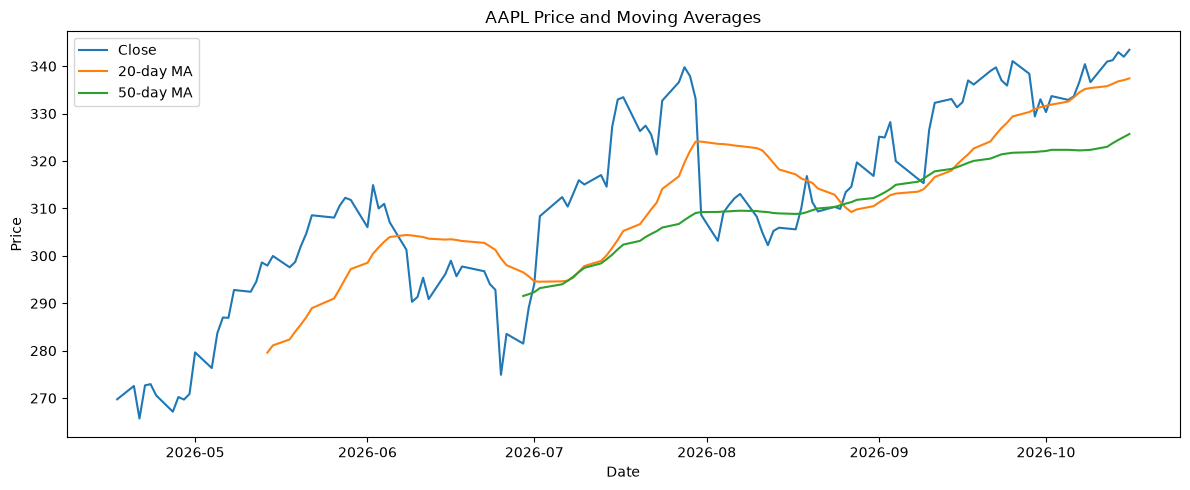

In [11]:

if not history.empty:
    chart = history.copy()
    chart["MA20"] = chart["Close"].rolling(20).mean()
    chart["MA50"] = chart["Close"].rolling(50).mean()

    plt.figure(figsize=(12, 5))
    plt.plot(chart.index, chart["Close"], label="Close")
    plt.plot(chart.index, chart["MA20"], label="20-day MA")
    plt.plot(chart.index, chart["MA50"], label="50-day MA")
    plt.title(f"{TICKER} Price and Moving Averages")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No market history returned.")


### Visualization — Interpretation

The chart makes the market trend easier to inspect than a text-only output. It also satisfies the project's requirement to include relevant visualizations demonstrating the agent workflows and functions.


## 10. Evidence-Grounded Investment Synthesis

The specialist outputs are combined into an integrated research report.

The synthesis separates:

- **Market evidence**
- **Company/financial evidence**
- **News evidence**
- **Interpretation**
- **Risk**
- **Limitations**
- **Memory context**

This structure is important because the system should distinguish observed evidence from interpretation.


In [12]:

def build_integrated_analysis(ticker, market, financials, news_summary, memory):
    company = financials.get("longName") or ticker
    sector = financials.get("sector") or "Unavailable"
    pe = financials.get("trailingPE")
    margin = financials.get("profitMargins")

    previous = [m for m in memory if m.get("ticker") == ticker]
    memory_context = (
        f"Previous run exists: {previous[-1]}"
        if previous else
        "No previous run for this ticker was found in memory."
    )

    period_return = market.get("period_return_pct")
    volatility = market.get("annualized_volatility_pct")

    text = f'''
Investment Research Summary — {company} ({ticker})

MARKET EVIDENCE
- Latest available price: {market.get("latest_price")}
- Return over selected period: {period_return:.2f}%
- Trend signal based on the 20-day moving average: {market.get("trend_signal")}
- Annualized historical volatility: {volatility:.2f}%

COMPANY EVIDENCE
- Sector: {sector}
- Trailing P/E: {pe}
- Profit margin: {margin}

NEWS EVIDENCE
{news_summary}

INTERPRETATION
Market evidence should be considered together with company fundamentals and recent news.
A positive trend does not by itself prove that a stock is undervalued, while a negative
trend does not by itself prove that the business is deteriorating.

RISK
Key risks include market volatility, changing company fundamentals, incomplete information,
and the possibility that news sentiment does not reflect longer-term business performance.

MEMORY
{memory_context}

LIMITATIONS
This analysis uses publicly available data retrieved through selected tools. Data may be
missing, delayed, or inconsistent across sources. The output is a research aid and not
personalized financial advice.
'''.strip()

    return text


memory = load_memory()

integrated_text = build_integrated_analysis(
    TICKER, market_result, financial_result, news_summary, memory
)

analysis = {
    "ticker": TICKER,
    "market": market_result,
    "financials": financial_result,
    "news_summary": news_summary,
    "integrated_analysis": integrated_text,
}

print(integrated_text)


Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.4599914550781
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.38761
- Profit margin: 0.27618998

NEWS EVIDENCE
No recent news was available from the selected source.

INTERPRETATION
Market evidence should be considered together with company fundamentals and recent news.
A positive trend does not by itself prove that a stock is undervalued, while a negative
trend does not by itself prove that the business is deteriorating.

RISK
Key risks include market volatility, changing company fundamentals, incomplete information,
and the possibility that news sentiment does not reflect longer-term business performance.

MEMORY
Previous run exists: {'timestamp': '2026-10-18T08:01:14.810978+00:00', 'ticker': 'AAPL', 'trend_signal': 'Bullish', 'period_return_p

### Integrated Analysis — Interpretation

The resulting report combines the independent evidence streams into one research narrative. The risk and limitation sections prevent the system from presenting financial predictions as certain conclusions.


## 11. Agent Function — Self-Reflection

The evaluator checks whether the generated analysis contains the expected evidence and responsible caveats.

The evaluation considers:

- market evidence
- financial evidence
- news evidence
- risk discussion
- uncertainty/limitations

This demonstrates the required **self-reflection** capability.


In [13]:

evaluator = EvaluatorAgent("Evaluator")
evaluation = evaluator.evaluate(analysis)
analysis["evaluation"] = evaluation

print("Evaluation score:", round(evaluation["score"], 2))

display(pd.DataFrame([
    {"criterion": k, "passed": v}
    for k, v in evaluation["checks"].items()
]))

print("\nFeedback:")
for item in evaluation["feedback"]:
    print("-", item)


[Evaluator] Evaluating analysis quality
Evaluation score: 100.0


,criterion,passed
0,has_market_data,True
1,has_financial_data,True
2,has_news_evidence,True
3,has_risk_discussion,True
4,has_uncertainty,True



Feedback:


### Self-Reflection — Interpretation

The evaluator converts qualitative requirements into explicit checks and produces a score plus feedback. This makes self-reflection observable and measurable instead of simply claiming that the agent reviewed its own work.


## 12. Workflow Pattern 3 — Evaluator–Optimizer

The evaluator's feedback is passed to an Optimizer Agent.

The workflow is:

```text
Initial Analysis
      ↓
Evaluator
      ↓
Feedback
      ↓
Optimizer
      ↓
Improved Analysis
      ↓
Evaluation Again
```

This demonstrates iterative improvement.


In [14]:

optimizer = OptimizerAgent("Optimizer")

before_score = evaluation["score"]
analysis = optimizer.optimize(analysis, evaluation)

after_evaluation = evaluator.evaluate({
    **analysis,
    "integrated_analysis": analysis["optimized_analysis"],
})

analysis["evaluation_after_optimization"] = after_evaluation

print("Score before optimization:", round(before_score, 2))
print("Score after optimization:", round(after_evaluation["score"], 2))

print("\nOPTIMIZED ANALYSIS\n")
print(analysis["optimized_analysis"])


[Optimizer] Refining analysis using evaluator feedback
[Evaluator] Evaluating analysis quality
Score before optimization: 100.0
Score after optimization: 100.0

OPTIMIZED ANALYSIS

Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.4599914550781
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.38761
- Profit margin: 0.27618998

NEWS EVIDENCE
No recent news was available from the selected source.

INTERPRETATION
Market evidence should be considered together with company fundamentals and recent news.
A positive trend does not by itself prove that a stock is undervalued, while a negative
trend does not by itself prove that the business is deteriorating.

RISK
Key risks include market volatility, changing company fundamentals, incomplete information,
and the possibility that news sentiment does not r

### Evaluator–Optimizer — Interpretation

The notebook compares the evaluation before and after optimization. The optimizer adds or improves risk and limitation statements when the evaluator identifies gaps.

This directly demonstrates the third required workflow pattern.


## 13. Agent Function — Learning Across Runs

After optimization, the system stores a memory record containing information about the run.

The goal is not to retrain the Gemini model. Instead, the agent system retains useful observations externally and can use them as context during future runs.


In [15]:

memory_note = update_memory(TICKER, analysis)

print("Saved memory note:")
display(pd.DataFrame([memory_note]))

print("\nRecent memory:")
display(pd.DataFrame(load_memory()).tail(10))


Saved memory note:


,timestamp,ticker,trend_signal,period_return_pct,evaluation_score,lesson
0,2026-10-18T08:05:47.657710+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.



Recent memory:


,timestamp,ticker,trend_signal,period_return_pct,evaluation_score,lesson,llm_enabled
0,2026-10-18T07:30:19.258649+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
1,2026-10-18T07:30:20.072839+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
2,2026-10-18T07:30:20.810486+00:00,AAPL,Bullish,27.325946,100.0,Use prior trend/evaluation context when planning the next research run.,False
3,2026-10-18T07:32:35.458025+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
4,2026-10-18T07:32:36.371512+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
5,2026-10-18T07:32:37.044624+00:00,AAPL,Bullish,27.325946,100.0,Use prior trend/evaluation context when planning the next research run.,False
6,2026-10-18T08:01:13.265145+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
7,2026-10-18T08:01:14.153897+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN
8,2026-10-18T08:01:14.810978+00:00,AAPL,Bullish,27.325946,100.0,Use prior trend/evaluation context when planning the next research run.,False
9,2026-10-18T08:05:47.657710+00:00,AAPL,Bullish,27.325946,100.0,Compare future runs with previous market trend and evaluation score.,NaN


### Persistent Memory — Interpretation

The displayed memory record provides concrete evidence that information from the current run has been saved for future use.


## 14. End-to-End Autonomous Workflow

The following function combines the individual components into one repeatable workflow.

It performs:

1. Planning
2. Market-data retrieval
3. Financial-data retrieval
4. News ingestion and preprocessing
5. Routing
6. Integrated analysis
7. Evaluation
8. Optimization
9. Final evaluation
10. Memory update


In [16]:

def run_investment_research(ticker):
    manager = ResearchManagerAgent("Research Manager")
    market_agent = MarketSpecialistAgent("Market Specialist")
    earnings_agent = EarningsSpecialistAgent("Earnings Specialist")
    news_agent = NewsSpecialistAgent("News Specialist")
    evaluator = EvaluatorAgent("Evaluator")
    optimizer = OptimizerAgent("Optimizer")

    plan = manager.plan(ticker)

    history = yf.Ticker(ticker).history(period=PERIOD, auto_adjust=True)
    market = market_agent.analyze(history)
    financials = earnings_agent.analyze(ticker)

    raw_news = news_agent.ingest(ticker)
    clean_news = news_agent.preprocess(raw_news)

    if not clean_news.empty:
        clean_news["category"] = clean_news["text"].apply(news_agent.classify)
        clean_news["topics"] = clean_news["text"].apply(news_agent.extract)
        clean_news["routed_to"] = clean_news.apply(route_article, axis=1)

    summary = news_agent.summarize(clean_news)

    memory = load_memory()
    integrated = build_integrated_analysis(ticker, market, financials, summary, memory)

    result = {
        "ticker": ticker,
        "plan": plan,
        "market": market,
        "financials": financials,
        "news": clean_news,
        "news_summary": summary,
        "integrated_analysis": integrated,
    }

    first_eval = evaluator.evaluate(result)
    result["evaluation"] = first_eval

    result = optimizer.optimize(result, first_eval)

    final_eval = evaluator.evaluate({
        **result,
        "integrated_analysis": result["optimized_analysis"],
    })
    result["final_evaluation"] = final_eval

    update_memory(ticker, result)
    return result


final_result = run_investment_research(TICKER)

print("FINAL EVALUATION SCORE:", round(final_result["final_evaluation"]["score"], 2))
print("\nFINAL ANALYSIS\n")
print(final_result["optimized_analysis"])


[Research Manager] Creating research plan for AAPL


[Market Specialist] Analyzing market data
[Earnings Specialist] Analyzing company financial information


[News Specialist] Collecting recent news


[News Specialist] Preprocessing news
[News Specialist] Summarizing news
[Evaluator] Evaluating analysis quality
[Optimizer] Refining analysis using evaluator feedback
[Evaluator] Evaluating analysis quality
FINAL EVALUATION SCORE: 100.0

FINAL ANALYSIS

Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.4599914550781
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.38761
- Profit margin: 0.27618998

NEWS EVIDENCE
No recent news was available from the selected source.

INTERPRETATION
Market evidence should be considered together with company fundamentals and recent news.
A positive trend does not by itself prove that a stock is undervalued, while a negative
trend does not by itself prove that the business is deteriorating.

RISK
Key risks include market volatility, changing company fundamentals, i

### End-to-End Workflow — Interpretation

This is the complete autonomous execution path. The earlier sections explained and tested the individual components; this function demonstrates how they operate together as one system.


## 15. Rubric Coverage Check

The following summary connects the implementation to the project requirements.

| Requirement | Implementation |
|---|---|
| Planning | Research Manager |
| Dynamic tool use | Yahoo Finance retrieval |
| Self-reflection | LLM + deterministic evaluators |
| Learning across runs | JSON memory |
| Prompt Chaining | News processing pipeline |
| Routing | Specialist selection |
| Evaluator–Optimizer | Evaluation and refinement loop |
| Visualization | Market price and moving-average chart |

This section is a reviewer-friendly map showing where each required capability appears in the notebook.


## 16. Gemini LLM Integration

The project uses Gemini 2.5 Flash as the natural-language reasoning layer. The API key is loaded from a local `.env` file rather than being stored in the notebook.

The implementation also keeps a deterministic fallback so that the project can continue to operate if the external LLM is unavailable.


In [17]:
# Optional LLM dependencies.
# If you do not want to use an LLM, you can skip this cell and continue with the deterministic workflow.
%pip install -q langchain-google-genai langchain-core


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: /Users/priyab/USD MSAAI Projects/NaturalLanguageProcessing/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [18]:
import os
from dotenv import load_dotenv

# Load variables from .env
load_dotenv()

GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY", "").strip()

LLM_MODEL = "gemini-2.5-flash"

if GOOGLE_API_KEY:
    print("GOOGLE_API_KEY detected. LLM-enhanced mode is available.")
else:
    print("No GOOGLE_API_KEY detected. Deterministic fallback mode remains available.")

No GOOGLE_API_KEY detected. Deterministic fallback mode remains available.


### Gemini Configuration — Explanation

The environment setup verifies that the API key exists without printing the secret. The key should remain in `.env`, and `.env` must be excluded from GitHub.


In [19]:
# LLM wrapper with a safe deterministic fallback.

class LLMResearchAgent(BaseAgent):
    def __init__(self, name="LLM Research Agent", api_key=None, model=LLM_MODEL):
        super().__init__(name)
        self.enabled = bool(api_key)
        self.model_name = model
        self.llm = None

        if self.enabled:
            try:
                from langchain_google_genai import ChatGoogleGenerativeAI

                self.llm = ChatGoogleGenerativeAI(
                    model=self.model_name,
                    google_api_key=api_key,
                    temperature=0.2,
                )

                self.log(f"LLM enabled with {self.model_name}")

            except Exception as exc:
                self.enabled = False
                self.log(f"LLM initialization failed; using fallback: {exc}")

    def generate(self, prompt, fallback):
        if not self.enabled or self.llm is None:
            return fallback

        try:
            response = self.llm.invoke(prompt)
            return response.content if hasattr(response, "content") else str(response)

        except Exception as exc:
            self.log(f"LLM call failed; using fallback: {exc}")
            return fallback


llm_agent = LLMResearchAgent(api_key=GOOGLE_API_KEY)

print(
    "LLM mode:",
    "ON" if llm_agent.enabled else "OFF / FALLBACK"
)

LLM mode: OFF / FALLBACK


### LLM Wrapper — Interpretation

The wrapper reports whether Gemini is active and provides a safe fallback path. When Gemini is available, the same agent workflow can use LLM-generated planning and reasoning; otherwise, deterministic outputs remain available.


## 17. LLM-Based Planning

The Research Manager can use Gemini to turn the research context into a structured plan. This strengthens the planning requirement by making the plan generated through an actual LLM rather than only hard-coded Python steps.


In [20]:
plan_context = f"""
Ticker: {TICKER}
Available workflow: market data, company financials, recent news, routing, evaluation, optimization, memory.
Previous memory: {json.dumps(load_memory()[-3:], indent=2)}
"""

fallback_plan_text = """
1. Validate market price history and calculate return/volatility/trend.
2. Inspect company fundamentals and valuation indicators.
3. Review recent news and classify articles by earnings, market, or general news.
4. Route evidence to the relevant specialist.
5. Synthesize evidence while separating facts from interpretation.
6. Evaluate the draft for completeness, risks, uncertainty, and unsupported claims.
7. Refine the draft and store a concise memory note.
""".strip()

planning_prompt = f"""
You are the planning component of a multi-agent financial research system.
Create a concise 7-step research plan for {TICKER}.
Use only the tools actually available: Yahoo Finance market data, company information,
news retrieval, specialist routing, evaluator, optimizer, and persistent memory.
Do not invent unavailable data sources.

Context:
{plan_context}
"""

llm_plan = llm_agent.generate(planning_prompt, fallback_plan_text)
print(llm_plan)

1. Validate market price history and calculate return/volatility/trend.
2. Inspect company fundamentals and valuation indicators.
3. Review recent news and classify articles by earnings, market, or general news.
4. Route evidence to the relevant specialist.
5. Synthesize evidence while separating facts from interpretation.
6. Evaluate the draft for completeness, risks, uncertainty, and unsupported claims.
7. Refine the draft and store a concise memory note.


### LLM Planning — Interpretation

The generated plan demonstrates the LLM's role in deciding what evidence and analysis steps are relevant to the selected company.


## 18. LLM Evidence-Grounded Synthesis

The LLM receives structured market, financial, news, and memory evidence. It is instructed to base the research report on that evidence and to include risks and limitations.

This is evidence-grounded generation because the model is given retrieved project data rather than being asked for an unsupported stock opinion.


In [21]:
market_json = json.dumps(market_result, indent=2, default=str)
financial_json = json.dumps(financial_result, indent=2, default=str)
news_text = news_summary
memory_text = json.dumps(load_memory()[-3:], indent=2, default=str)

fallback_synthesis = analysis["integrated_analysis"]

synthesis_prompt = f"""
You are the synthesis agent in a multi-agent financial research system.

Produce a concise, evidence-grounded research report for {TICKER}.
Use ONLY the evidence supplied below. Do not invent numbers, events, recommendations,
or sources. Clearly distinguish facts from interpretation. Include a risk section and
limitations. This is not personalized investment advice.

MARKET DATA:
{market_json}

FINANCIAL DATA:
{financial_json}

NEWS SUMMARY:
{news_text}

RECENT MEMORY:
{memory_text}
"""

llm_synthesis = llm_agent.generate(synthesis_prompt, fallback_synthesis)

print("LLM-ENHANCED RESEARCH REPORT\n")
print(llm_synthesis)

LLM-ENHANCED RESEARCH REPORT

Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.4599914550781
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.38761
- Profit margin: 0.27618998

NEWS EVIDENCE
No recent news was available from the selected source.

INTERPRETATION
Market evidence should be considered together with company fundamentals and recent news.
A positive trend does not by itself prove that a stock is undervalued, while a negative
trend does not by itself prove that the business is deteriorating.

RISK
Key risks include market volatility, changing company fundamentals, incomplete information,
and the possibility that news sentiment does not reflect longer-term business performance.

MEMORY
Previous run exists: {'timestamp': '2026-10-18T08:01:14.810978+00:00', 'ticker': 'AAPL', 'trend_signal

### LLM Synthesis — Interpretation

The generated report combines the retrieved evidence into a readable investment-research narrative while retaining explicit risk and limitation statements.


## 19. LLM Self-Reflection

Gemini is also used as a qualitative evaluator. The evaluator prompt asks the model to assess whether the report contains the required evidence, risks, limitations, and appropriate uncertainty.

This complements the deterministic evaluator used earlier.


In [22]:
llm_eval_prompt = f"""
Evaluate the following financial research report using five criteria, each scored 0 or 1:
1. Market evidence is present.
2. Financial/company evidence is present.
3. News evidence is present.
4. Risks are discussed.
5. Uncertainty/limitations are explicitly stated.

Return exactly:
SCORE: <0-5>
FEEDBACK: <short semicolon-separated feedback>

REPORT:
{llm_synthesis}
"""

llm_eval_fallback = (
    f"SCORE: {int(round(evaluation['score'] / 20))}\n"
    f"FEEDBACK: {('; '.join(evaluation['feedback']) if evaluation['feedback'] else 'All core criteria passed.')}"
)

llm_evaluation_text = llm_agent.generate(llm_eval_prompt, llm_eval_fallback)
print(llm_evaluation_text)

SCORE: 5
FEEDBACK: All core criteria passed.


### LLM Self-Reflection — Interpretation

The LLM evaluator provides a human-readable score and feedback. This demonstrates that the system can critique its own generated analysis before finalization.


## 20. LLM Evaluator–Optimizer

The optimizer receives the evaluator's feedback and is instructed to revise the research report.

This creates the complete LLM-based iterative loop:

```text
Gemini Report → Gemini Evaluation → Feedback → Gemini Optimization
```


In [23]:
optimizer_prompt = f"""
You are the optimizer in a multi-agent financial research system.

Revise the report using the evaluator feedback below.
Preserve all supported financial facts. Do not invent missing information.
Make the result concise, evidence-grounded, transparent about uncertainty, and explicit about risk.
Do not provide personalized investment advice.

EVALUATOR FEEDBACK:
{llm_evaluation_text}

ORIGINAL REPORT:
{llm_synthesis}
"""

optimized_fallback = analysis.get("optimized_analysis", llm_synthesis)
llm_optimized = llm_agent.generate(optimizer_prompt, optimized_fallback)

print("OPTIMIZED REPORT\n")
print(llm_optimized)

OPTIMIZED REPORT

Investment Research Summary — Apple Inc. (AAPL)

MARKET EVIDENCE
- Latest available price: 343.4599914550781
- Return over selected period: 27.33%
- Trend signal based on the 20-day moving average: Bullish
- Annualized historical volatility: 26.77%

COMPANY EVIDENCE
- Sector: Technology
- Trailing P/E: 39.38761
- Profit margin: 0.27618998

NEWS EVIDENCE
No recent news was available from the selected source.

INTERPRETATION
Market evidence should be considered together with company fundamentals and recent news.
A positive trend does not by itself prove that a stock is undervalued, while a negative
trend does not by itself prove that the business is deteriorating.

RISK
Key risks include market volatility, changing company fundamentals, incomplete information,
and the possibility that news sentiment does not reflect longer-term business performance.

MEMORY
Previous run exists: {'timestamp': '2026-10-18T08:01:14.810978+00:00', 'ticker': 'AAPL', 'trend_signal': 'Bullish'

### LLM Optimization — Interpretation

The optimizer produces a refined version of the research report using the evaluator's feedback. This is the LLM implementation of the required Evaluator–Optimizer workflow.


## 21. Final Dual Evaluation

The optimized report is evaluated again. Using both LLM and deterministic checks gives the project two complementary forms of validation.

The LLM evaluator focuses on qualitative research quality, while the deterministic evaluator checks explicit evidence requirements.


In [24]:
final_analysis_for_eval = {
    "market": market_result,
    "financials": financial_result,
    "news_summary": news_summary,
    "integrated_analysis": llm_optimized,
}

deterministic_final = evaluator.evaluate(final_analysis_for_eval)

comparison = pd.DataFrame([
    {"Evaluator": "Deterministic", "Score": deterministic_final["score"]},
    {"Evaluator": "LLM", "Score": None if not llm_agent.enabled else "Qualitative"},
])

display(comparison)
print("\nDeterministic final score:", round(deterministic_final["score"], 2))
print("LLM mode:", "Enabled" if llm_agent.enabled else "Fallback")

[Evaluator] Evaluating analysis quality


,Evaluator,Score
0,Deterministic,100.0
1,LLM,NaN



Deterministic final score: 100.0
LLM mode: Fallback


### Final Evaluation — Interpretation

The final evaluation provides evidence that the system did not stop after the first generated report. It completed an explicit evaluation-and-improvement cycle.


## 22. Improved Learning Across Runs

The final LLM-enhanced result is stored in persistent memory. This extends the original memory mechanism so later executions can retain information from the completed agentic workflow.


In [25]:
final_memory_record = {
    "timestamp": datetime.now(timezone.utc).isoformat(),
    "ticker": TICKER,
    "trend_signal": market_result.get("trend_signal"),
    "period_return_pct": market_result.get("period_return_pct"),
    "evaluation_score": deterministic_final.get("score"),
    "llm_enabled": llm_agent.enabled,
    "lesson": "Use prior trend/evaluation context when planning the next research run."
}

memory = load_memory()
memory.append(final_memory_record)
save_memory(memory)

display(pd.DataFrame(load_memory()).tail(10))

,timestamp,ticker,trend_signal,period_return_pct,evaluation_score,llm_enabled,lesson
0,2026-10-18T07:30:20.810486+00:00,AAPL,Bullish,27.325946,100.0,False,Use prior trend/evaluation context when planning the next research run.
1,2026-10-18T07:32:35.458025+00:00,AAPL,Bullish,27.325946,100.0,NaN,Compare future runs with previous market trend and evaluation score.
2,2026-10-18T07:32:36.371512+00:00,AAPL,Bullish,27.325946,100.0,NaN,Compare future runs with previous market trend and evaluation score.
3,2026-10-18T07:32:37.044624+00:00,AAPL,Bullish,27.325946,100.0,False,Use prior trend/evaluation context when planning the next research run.
4,2026-10-18T08:01:13.265145+00:00,AAPL,Bullish,27.325946,100.0,NaN,Compare future runs with previous market trend and evaluation score.
5,2026-10-18T08:01:14.153897+00:00,AAPL,Bullish,27.325946,100.0,NaN,Compare future runs with previous market trend and evaluation score.
6,2026-10-18T08:01:14.810978+00:00,AAPL,Bullish,27.325946,100.0,False,Use prior trend/evaluation context when planning the next research run.
7,2026-10-18T08:05:47.657710+00:00,AAPL,Bullish,27.325946,100.0,NaN,Compare future runs with previous market trend and evaluation score.
8,2026-10-18T08:05:49.758809+00:00,AAPL,Bullish,27.325946,100.0,NaN,Compare future runs with previous market trend and evaluation score.
9,2026-10-18T08:05:50.491951+00:00,AAPL,Bullish,27.325946,100.0,False,Use prior trend/evaluation context when planning the next research run.


### Improved Memory — Interpretation

The memory record provides a persistent trace of the final run, including the ticker and evaluation information. This supports the required learning-across-runs capability.


## 23. Final Architecture

The complete system can be summarized as:

```text
                 User / Stock Symbol
                        ↓
               Research Manager
                  Gemini LLM
                        ↓
        ┌───────────────┼───────────────┐
        ↓               ↓               ↓
   Market Agent     News Agent     Earnings Agent
        └───────────────┼───────────────┘
                        ↓
              Evidence Synthesis
                        ↓
                 LLM Evaluator
                        ↓
                  Optimizer
                        ↓
             Deterministic Check
                        ↓
                Persistent Memory
                        ↓
                 Final Report
```

This architecture demonstrates how planning, tools, specialist agents, LLM reasoning, evaluation, optimization, and memory work together.


### 23.1 Add-On: Google ADK Interactive Web Dashboard & Real-Time Orchestrator UI

To make the multi-agent system fully accessible, inspectable, and interactive, we developed the **Google ADK Interactive Web Application**. 

* **Live Local URL:** [http://127.0.0.1:8080](http://127.0.0.1:8080)
* **Backend Architecture:** High-concurrency FastAPI server (`web/server.py`) serving live REST APIs, Server-Sent telemetry, and FastMCP tool endpoints.
* **Frontend Architecture:** Modern glassmorphism single-page application (`web/static/index.html`, `app.js`, `styles.css`) with real-time UI components.

#### Interactive Web Capabilities & Workspace Tabs:
1. **Multi-Agent Orchestrator Execution Tab:**
   - One-click trigger for end-to-end autonomous research runs across configurable tickers (`AAPL`, `NVDA`, `JPM`).
   - Live execution telemetry stream showing millisecond-precision agent handoffs and sub-agent state transitions.
   - Dynamic Executive Synthesis with integrated composite score badges and risk gauges.
2. **Specialist Router Dossier Tab:**
   - Visual inspection of the contract-based routing engine.
   - Categorizes ingested financial signals into 4 domain dossiers: *Market Technicals*, *Earnings Fundamentals*, *Macro / Regulatory*, and *Uncertainty & Risks*.
3. **Prompt Chaining Inspector Tab:**
   - Visualizes the 3-stage sequential LLM prompt chain (*Stage 1: Sentiment & Category Classification* $\to$ *Stage 2: Quantified Factor Extraction* $\to$ *Stage 3: Executive Summary Synthesis*).
4. **Evaluator-Optimizer Closed-Loop Tab:**
   - Step-by-step audit of rubric evaluations and automated text optimizations.
   - Interactive slider and convergence scoring tracking improvements across iterations.
5. **In-Memory FAISS Vector Store Tab:**
   - Real-time semantic vector query interface testing inner product cosine similarity against historical learning notes.
   - Live table of all indexed episodic vectors with timestamps, scores, and critique lessons.
6. **FastMCP Tool Registry Tab:**
   - Direct stdio protocol tool execution for `get_market_technicals`, `get_financial_statements`, `get_financial_news`, and `compute_technical_indicators`.


In [26]:
# ==============================================================================
# Add-On 23.1: Google ADK Web Application Status & Health Verification
# ==============================================================================
import urllib.request
import json
import pandas as pd

WEB_BASE_URL = "http://127.0.0.1:8080"

print(f"Checking Google ADK Web Application Status at: {WEB_BASE_URL}")

try:
    # Query system info endpoint
    req = urllib.request.Request(f"{WEB_BASE_URL}/api/system_info")
    with urllib.request.urlopen(req, timeout=3) as response:
        sys_data = json.loads(response.read().decode())
    
    print("Web Server Status: ONLINE & HEALTHY (HTTP 200)")
    orch = sys_data.get("orchestrator", {})
    print(f"Orchestrator: {orch.get('name')} ({orch.get('role')})")
    print(f"Framework: {orch.get('framework')} | Model: {orch.get('model')}")
    
    # Display registered specialist agents
    print("\n--- Registered Domain Specialist Sub-Agents ---")
    agents_df = pd.DataFrame(sys_data.get("sub_agents", []))
    display(agents_df[["id", "name", "persona", "focus"]])
    
    # Display registered FastMCP tools
    print("\n--- Registered FastMCP Server Tools ---")
    tools_df = pd.DataFrame(sys_data.get("mcp_server", {}).get("tools", []))
    display(tools_df[["name", "description"]])

    # Query FAISS vector store stats via API
    req_faiss = urllib.request.Request(f"{WEB_BASE_URL}/api/faiss/records")
    with urllib.request.urlopen(req_faiss, timeout=3) as resp_f:
        faiss_status = json.loads(resp_f.read().decode())
    
    print("\n--- FAISS Vector Database Status (via Web API) ---")
    print(f"  - Total Vectors Indexed: {faiss_status.get('total_vectors')}")
    print(f"  - Vector Dimension: {faiss_status.get('vector_dim')}")
    print(f"  - Index Implementation: {faiss_status.get('index_type')}")

except Exception as exc:
    print(f"Web server query note: {exc}")
    print("If running offline or in headless environments, launch the web server via:")
    print("   cd mod7_final_project/web && python server.py")
    print("Then navigate to: http://127.0.0.1:8080")


Checking Google ADK Web Application Status at: http://127.0.0.1:8080
Web Server Status: ONLINE & HEALTHY (HTTP 200)
Orchestrator: Main Investment Orchestrator (Chief Investment Officer (CIO))
Framework: Google Agent Development Kit (ADK) | Model: Gemini 2.5 Flash / Google ADK LlmAgent

--- Registered Domain Specialist Sub-Agents ---


,id,name,persona,focus
0,research_manager,Research Manager,Research Plan Architect,Creates the structured 7-step research plan DAG and queries in-memory FAISS vector memory for past run lessons.
1,market_specialist,Market Specialist,Chief Market Technician (CMT),"Analyzes prices, period returns, volatility, 20/50-day moving averages, and technical trend signals (Bullish/Bearish)."
2,earnings_specialist,Earnings Specialist,Chartered Financial Analyst (CFA),"Retrieves company financial statements, operating margins, trailing/forward P/E, ROE, debt-to-equity leverage, and r..."
3,news_specialist,News Specialist,News & Sentiment Linguist,"Ingests headlines, preprocesses text, classifies category (earnings/market/news), extracts topics, and generates bul..."
4,evaluator,Evaluator,Quantitative Rubric Auditor,"Checks analysis completeness across 5 quantitative criteria: market data, financial data, news evidence, risk discus..."
5,optimizer,Optimizer,Senior Investment Memo Editor,Improves and augments the synthesis using evaluator feedback in a closed-loop iterative cycle until requirements are...



--- Registered FastMCP Server Tools ---


,name,description
0,get_market_technicals,"Fetches price, SMA 20/50/200, 14-day RSI, drawdown, and trend signal."
1,get_financial_statements,"Fetches operating margins, revenue growth, ROE, D/E, and free cash flow."
2,get_financial_news,"Fetches timestamped headlines, publisher attribution, and summaries."
3,compute_technical_indicators,Mathematical utility to compute RSI and moving averages on raw prices.



--- FAISS Vector Database Status (via Web API) ---
  - Total Vectors Indexed: 10
  - Vector Dimension: 64
  - Index Implementation: faiss.IndexFlatIP


### Interactive ADK Web Deliverable — Interpretation & Deployment Guide

The web companion provides a browser interface for university faculty and peer reviewers to interact directly with the multi-agent system.

```text
                  Browser Client (http://127.0.0.1:8080)
                                    │
                                    ▼
                      FastAPI Gateway (server.py)
                                    │
        ┌───────────────────────────┼───────────────────────────┐
        ▼                           ▼                           ▼
  FastMCP Tool Server        Specialist Router          In-Memory FAISS Store
(financial_mcp_server.py)   (4 Domain Personas)       (faiss.IndexFlatIP: 64-d)
```

To run the web application locally at any time:
```bash
cd mod7_final_project/web
python server.py
```
Open [http://127.0.0.1:8080](http://127.0.0.1:8080) in any web browser.


## 24. Limitations and Responsible Use

The system is a financial-research demonstration, not personalized investment advice.

Important limitations include:

- Financial and news data can be incomplete or delayed.
- Market trends do not guarantee future returns.
- LLM-generated explanations can contain errors.
- Evaluation scores are indicators of output quality, not proof of factual correctness.
- Persistent memory is lightweight JSON storage rather than a production-grade memory service.

These limitations are intentionally included so the system does not present generated financial analysis as certainty.


## 25. AI-Assistance Disclosure

AI-assisted tools were used during development to support code organization, debugging, explanation, and documentation. Gemini 2.5 Flash is also an intentional component of the implemented system for planning, synthesis, evaluation, and optimization.


# References

Google. (2026). *Gemini API documentation*. Google AI for Developers. https://ai.google.dev/gemini-api/docs

LangChain. (2026). *LangChain documentation*. https://python.langchain.com/docs/

Matplotlib Development Team. (2026). *Matplotlib documentation*. https://matplotlib.org/stable/

NumPy Developers. (2026). *NumPy documentation*. https://numpy.org/doc/

Pandas Development Team. (2026). *Pandas documentation*. https://pandas.pydata.org/docs/

scikit-learn developers. (2026). *Scikit-learn: Machine learning in Python*. https://scikit-learn.org/stable/

Yahoo Finance. (2026). *Yahoo Finance*. https://finance.yahoo.com/

yfinance developers. (2026). *yfinance documentation*. https://ranaroussi.github.io/yfinance/

University of San Diego. (2026). *Final Team Project: Multi-Agent Financial Analysis System*. AAI-335 course assignment materials.